# arch: volatilidad financiera con GARCH

**Para qué sirve:** los precios son difíciles de predecir, pero la *volatilidad* (cuánto se mueve el precio) sí tiene memoria: tras un día agitado suele venir otro agitado. Los modelos GARCH capturan eso.

Casos prácticos de este notebook:
1. Descargar datos reales y ajustar un GARCH
2. Predecir la volatilidad de los próximos días
3. Calcular el Value at Risk (VaR) diario
4. Detectar el efecto apalancamiento (GJR-GARCH)
5. Test de raíz unitaria: ¿precios o retornos?

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model
from arch.unitroot import ADF

TICKER = "SPY"  # cámbialo por AAPL, BTC-USD, EURUSD=X...

## 1. Datos y modelo GARCH(p,q)
Usa datos reales de Yahoo Finance; si no hay conexión, simula una serie con volatilidad cambiante.

p: ARCH, shock reciente. Retorno al cuadrado del dia anterior

q: GARCH, memoria reciente. Varianza del dia anterior

In [4]:
try:
    import yfinance as yf
    precios = yf.download(TICKER, start="2015-01-01", progress=False, auto_adjust=True)["Close"].squeeze().dropna()
    assert len(precios) > 500
    print(f"Datos reales de {TICKER}: {len(precios)} días")
    
except Exception as e:
    print("Sin datos reales, simulando:", type(e).__name__)
    from arch.univariate import GARCH, ConstantMean, StudentsT
    sim = ConstantMean(None); sim.volatility = GARCH(1, 0, 1); sim.distribution = StudentsT()
    d = sim.simulate([0.05, 0.02, 0.1, 0.88, 6], 2500)
    precios = 100 * np.exp(d["data"].cumsum() / 100)
    precios.index = pd.bdate_range("2015-01-01", periods=len(precios))

retornos = 100 * np.log(precios).diff().dropna()  # ln(T_t / T_{t-1}) * 100

res = arch_model(retornos, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")
print(res.summary())

Datos reales de SPY: 2970 días
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                          SPY   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -3709.66
Distribution:      Standardized Student's t   AIC:                           7429.32
Method:                  Maximum Likelihood   BIC:                           7459.30
                                              No. Observations:                 2969
Date:                      Sat, Oct 24 2026   Df Residuals:                     2968
Time:                              11:14:36   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
------------------------------------------------------

/Users/alejandro/Desktop/Alejandro/Personal/Programacion/demos-arch-mapie/.venv/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/alejandro/Desktop/Alejandro/Personal/Programacion/demos-arch-mapie/.venv/lib/python3.15/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/alejandro/Desktop/Alejandro/Personal/Programacion/demos-arch-mapie/.venv/lib/python3.15/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will 

mu: retorno promedio diario
omega: Riesgo estructural o base
alpha: termino ARCH, impacto a sorpresas. Es decir si ayer hay una sorpresa que proporcion de la volatilidad de hoy es debido a ayer.
beta:  termino GARCH, inercia de mercado. Cuanto riesgo se arrastra a hoy
nu: grosor de colas pesadas de t student

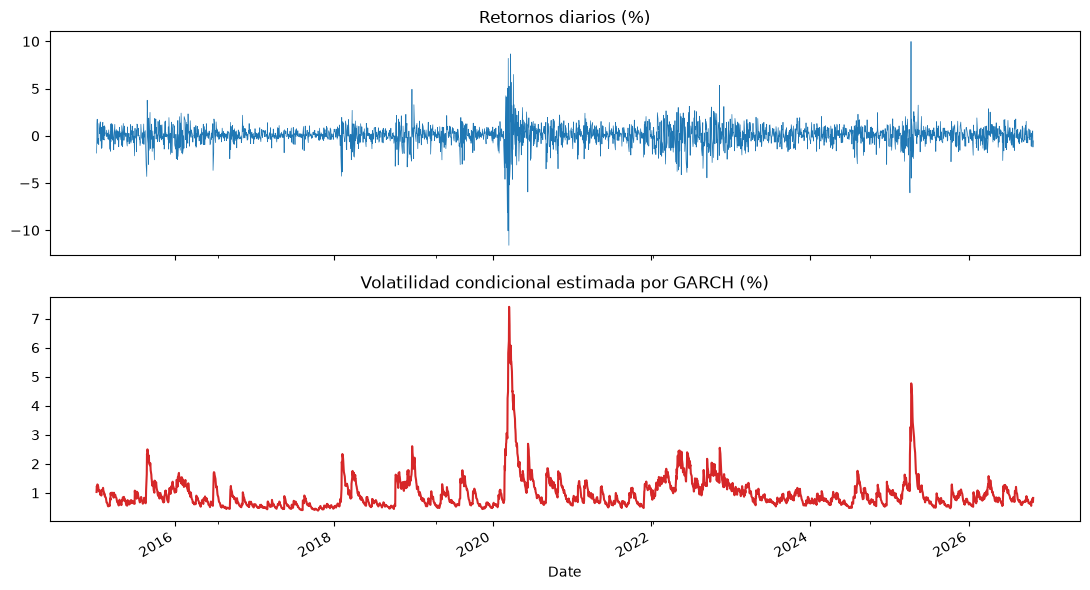

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
retornos.plot(ax=ax[0], lw=0.5, title="Retornos diarios (%)")
res.conditional_volatility.plot(ax=ax[1], color="C3", title="Volatilidad condicional estimada por GARCH (%)")
plt.tight_layout(); plt.show()

La volatilidad es una desv. est. de lo que se puede mover el precio ese dia. 1 desv est es el 68% de los escenarios.

Es condicional porque el riesgo de mañana no es un promedio fijo sino depende de la informacion de hoy. La volatilidad con GARCH no es constante sino que se basa en funcion del dia anterior

`alpha[1]` mide cuánto reacciona la volatilidad a un shock reciente y `beta[1]` cuánto persiste. Si `alpha + beta` está cerca de 1, la volatilidad tarda mucho en normalizarse (típico en bolsa).

## 2. Predicción de volatilidad a 10 días

In [ ]:
f = res.forecast(horizon=10) #desde la ultima observacion a 10 dias vista
print(f.variance.shape)
#vol = raiz de las varianzas  para el dia 10
vol_pred = np.sqrt(f.variance.iloc[-1])
vol_pred.index = [f"día +{i}" for i in range(1, 11)]
print(f"{vol_pred.round(3)}")
print(f"\nVolatilidad condicional anualizada en t: {res.conditional_volatility.iloc[-1] * np.sqrt(252):.1f}%") #in sample

# Contexto: último día observado vs. horizontes vs. largo plazo
omega, alpha, beta = res.params["omega"], res.params["alpha[1]"], res.params["beta[1]"]
vol_actual = res.conditional_volatility.iloc[-1]          # último día observado (in-sample)
vol_lp = np.sqrt(omega / (1 - alpha - beta))               # largo plazo
print(f"\nÚltimo día observado: {vol_actual:.3f}%")
print(f"Los 10 horizontes:    {np.sqrt(f.variance.iloc[-1]).round(3).values}")
print(f"Largo plazo:          {vol_lp:.3f}%")
print(f"Persistencia alpha+beta = {alpha + beta:.3f}  |  vida media del shock = {np.log(0.5) / np.log(alpha + beta):.0f} días")

ax = vol_pred.plot(marker="o", color="C0", title="Volatilidad diaria prevista (%): reversión a la media", figsize=(8, 3.5))
ax.axhline(vol_actual, color="C3", ls="--", label=f"último día observado ({vol_actual:.2f})")
ax.set_ylim(min(vol_pred.min(), vol_actual) * 0.97, max(vol_pred.max(), vol_actual) * 1.03)  # zoom a lo que se ve
ax.set_title(ax.get_title() + f"\nlargo plazo = {vol_lp:.2f}% (fuera de escala)")
ax.legend(); plt.tight_layout(); plt.show()

### ¿Por qué `vol_pred` no es igual a `conditional_volatility`?

- `res.conditional_volatility`: **pasado**. La $\sigma_t$ estimada para cada fecha ya observada (in-sample). Su último valor es la volatilidad del último día observado, no la de mañana.
- `f.variance` / `vol_pred`: **futuro**. La volatilidad esperada para los próximos 10 días de mercado (no de calendario), usando la información hasta el último dato.

**Reversión a la media.** La varianza prevista no se queda en el nivel actual, converge hacia la varianza de largo plazo:

$$\sigma^2_{LP} = \frac{\omega}{1-\alpha-\beta}$$

y la predicción a $h$ pasos es:

$$\mathbb{E}[\sigma^2_{t+h}] = \sigma^2_{LP} + (\alpha+\beta)^{\,h-1}\,\bigl(\sigma^2_{t+1} - \sigma^2_{LP}\bigr)$$

Qué es cada símbolo:

| Símbolo | Qué es |
|---|---|
| $\mathbb{E}[\sigma^2_{t+h}]$ | Varianza esperada $h$ días después del último dato (lo que da `f.variance`, columna `h.0h`) |
| $t$ | Último día observado (origen de la predicción) |
| $h$ | Horizonte: 1, 2, ..., 10 días de mercado |
| $\sigma^2_{t+1}$ | Varianza prevista para mañana ($h=1$). Ya conoce el shock del último día |
| $\sigma^2_{LP}$ | Varianza de largo plazo, $\omega/(1-\alpha-\beta)$: el nivel al que tiende la volatilidad |
| $\omega$ | Riesgo base: constante que fija el nivel de largo plazo |
| $\alpha$ | Reacción a la sorpresa de ayer (retorno al cuadrado) |
| $\beta$ | Inercia: cuánta varianza de ayer se arrastra a hoy |
| $\alpha+\beta$ | **Persistencia**: factor por el que se reduce cada día la distancia al largo plazo |
| $(\alpha+\beta)^{h-1}$ | Cuánto queda de esa distancia tras $h-1$ pasos. Cerca de 1: casi todo; cerca de 0: casi nada |
| $\sigma^2_{t+1}-\sigma^2_{LP}$ | Distancia inicial: cuánto se aleja mañana del largo plazo |

Lectura: la predicción a $h$ días es el largo plazo más lo que queda de la distancia inicial, que se encoge por el factor $(\alpha+\beta)$ cada día. En $h=1$ el factor vale 1 y la predicción es $\sigma^2_{t+1}$. Cuando $h$ crece, el factor tiende a 0 y la predicción tiende a $\sigma^2_{LP}$.

- Si hoy la volatilidad es **alta** (tras un shock), `vol_pred` empieza alta y **baja** hacia $\sigma_{LP}$.
- Si hoy es **baja**, `vol_pred` **sube** hacia ese nivel.
- Cuanto más lejos el horizonte, más se acerca a $\sigma_{LP}$.
- Con persistencia $\alpha+\beta$ cercana a 1 la convergencia es lenta y las diferencias son pequeñas; con persistencia baja, son grandes.

Por eso `vol_pred.mean()` es algo intermedio entre la volatilidad actual y la de largo plazo, y **no** coincide con `conditional_volatility.iloc[-1]`. Además, promediar volatilidades no es lo mismo que promediar varianzas (desigualdad de Jensen). Para la volatilidad esperada del periodo completo:

```python
np.sqrt(f.variance.iloc[-1].mean()) * np.sqrt(252)   # anualizada
```

La **vida media del shock** (días que tarda en disiparse la mitad de la desviación respecto al largo plazo) es $\ln(0.5)/\ln(\alpha+\beta)$.

## 3. Value at Risk (VaR) diario
"Con un 99% de confianza, mañana no perderé más de X%". Se usa el cuantil de los residuos estandarizados (simulación histórica filtrada), que respeta las colas gordas.

In [5]:
mu = res.params["mu"]
sigma_manana = np.sqrt(res.forecast(horizon=1).variance.iloc[-1, 0])
inversion = 10_000

for nivel in (0.95, 0.99):
    q = res.std_resid.dropna().quantile(1 - nivel)
    var_pct = -(mu + sigma_manana * q)
    print(f"VaR {nivel:.0%}: {var_pct:.2f}%  ->  con {inversion:,}€ se podrían perder más de {inversion * var_pct / 100:,.0f}€ el {1 - nivel:.0%} de los días")

VaR 95%: 1.34%  ->  con 10,000€ se podrían perder más de 134€ el 5% de los días
VaR 99%: 2.27%  ->  con 10,000€ se podrían perder más de 227€ el 1% de los días


In [6]:
# Backtest: ¿con qué frecuencia se superó el VaR 99%? Debería rondar el 1%
q99 = res.std_resid.dropna().quantile(0.01)
var99 = -(mu + res.conditional_volatility * q99)
violaciones = (retornos < -var99).mean()
print(f"Días en que la pérdida superó el VaR 99%: {violaciones:.2%} (esperado ~1%)")

Días en que la pérdida superó el VaR 99%: 1.01% (esperado ~1%)


## 4. Efecto apalancamiento: GJR-GARCH
En bolsa las caídas suelen disparar más la volatilidad que las subidas. El parámetro `o=1` lo modela.

**GJR** es un GARCH al que se le añade un término asimétrico:

$$\sigma^2_t = \omega + (\alpha + \gamma\, I_{t-1})\,\varepsilon^2_{t-1} + \beta\,\sigma^2_{t-1}, \qquad I_{t-1}=\begin{cases}1 & \varepsilon_{t-1}<0 \\ 0 & \varepsilon_{t-1}\ge 0\end{cases}$$

- $\varepsilon_{t-1}$: la sorpresa de ayer (retorno menos la media). $I$ vale 1 solo si fue negativa.
- Tras una **subida** el impacto en la varianza es $\alpha$. Tras una **caída** es $\alpha+\gamma$.
- `o=1` en `arch_model` es el número de términos asimétricos, y el parámetro resultante se llama `gamma[1]`.

### Valores de $\gamma$ (`gamma[1]`)

| Valor | Significado |
|---|---|
| $\gamma = 0$ | Sin asimetría: el modelo es un GARCH normal |
| $\gamma > 0$ | **Efecto apalancamiento**: las caídas aumentan la volatilidad más que las subidas de igual tamaño. Es lo típico en bolsa |
| $\gamma < 0$ | Lo contrario: las subidas suben más la volatilidad. Raro en acciones, posible en algunos activos (materias primas, divisas) |

Con $\gamma$ la persistencia pasa a ser $\alpha + \gamma/2 + \beta$, porque las caídas ocurren aproximadamente la mitad de los días.

### p-valor de `gamma[1]`
Contrasta la hipótesis $\gamma = 0$ (no hay asimetría).
- **p < 0,05**: $\gamma$ es significativamente distinto de 0, hay asimetría real.
- **p alto**: no se puede distinguir de 0, y el GARCH simple basta.

### AIC (Criterio de Información de Akaike)

$$AIC = 2k - 2\ln(L)$$

- $L$: verosimilitud del modelo (cuánto de bien explica los datos). Cuanto mayor, mejor.
- $k$: número de parámetros. El término $2k$ **penaliza la complejidad**.

Sirve para comparar modelos sobre **los mismos datos**: **menor AIC = mejor**, porque equilibra el ajuste con la sencillez. El GJR tiene un parámetro más que el GARCH, así que solo gana si mejora el ajuste lo suficiente para compensarlo.

| Diferencia de AIC | Lectura |
|---|---|
| < 2 | Prácticamente equivalentes |
| 4 – 7 | Evidencia moderada a favor del menor |
| > 10 | Evidencia fuerte a favor del menor |

El valor absoluto del AIC no significa nada por sí solo, solo importa la **diferencia** entre modelos. Existe también el **BIC** (`res.bic`), que penaliza más los parámetros adicionales ($k\ln n$ en lugar de $2k$) y favorece modelos más simples.

In [7]:
gjr = arch_model(retornos, vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")
print(f"AIC GARCH: {res.aic:.1f}   AIC GJR-GARCH: {gjr.aic:.1f}  (menor = mejor)")
print(f"gamma[1] = {gjr.params['gamma[1]']:.3f}, p-valor = {gjr.pvalues['gamma[1]']:.4f}")
print("-> gamma > 0 y significativo = las caídas aumentan más la volatilidad que las subidas")

AIC GARCH: 7429.3   AIC GJR-GARCH: 7333.2  (menor = mejor)
gamma[1] = 0.264, p-valor = 0.0000
-> gamma > 0 y significativo = las caídas aumentan más la volatilidad que las subidas


## 5. Test de raíz unitaria (ADF)
Antes de modelar una serie hay que saber si es estacionaria. Los precios normalmente no lo son; los retornos sí.

In [8]:
for nombre, serie in [("Precios", np.log(precios)), ("Retornos", retornos)]:
    adf = ADF(serie, trend="c")
    print(f"{nombre:9s} estadístico={adf.stat:7.2f}  p-valor={adf.pvalue:.4f}  ->",
          "estacionaria" if adf.pvalue < 0.05 else "NO estacionaria (raíz unitaria)")

Precios   estadístico=  -0.14  p-valor=0.9453  -> NO estacionaria (raíz unitaria)
Retornos  estadístico= -17.72  p-valor=0.0000  -> estacionaria
